# Intelligent Agents: Reflex-Based Agents for GridHunt (Multi-agent Environment)

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and several hunter agents and the monster agent move around in the arena. A hunter catches the monster if she/he moves on the same square the monster currently occupies. The hunters compete fow who catches the monster first. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunters are randomly placed in the arena environment. The hunters and the monster
    can move around, but cannot leave the arena. Since there are three agents involved, this is a competitive multi-agent environment.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena and the location of the monster.  

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [1]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function, n = 30, max_steps = 100, visualize = False, animation = False):
    """
    Simulate an arena where two hunter agent tries to catch a monster agent.

    Parameters:
    hunter_1_agent_function and hunter_2_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_1_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n-1, size=2)
    hunter_2_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n-1, size=2)    
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step}:")
        print(f"Hunter 1 is at '{hunter_1_pos}'; Hunter 2 is at '{hunter_2_pos}'; Monster is at '{monster_pos}'\n")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_1_pos[0], hunter_1_pos[1]] = '1'
        arena[hunter_2_pos[0], hunter_2_pos[1]] = '2'
        print("\n".join("".join(row) for row in arena))

    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_1_pos, monster_pos):
            if visualize:
                print(f"Hunter 1 caught the monster in {step} steps!")
            return ("1", step)
        
        if np.array_equal(hunter_2_pos, monster_pos):
            if visualize:
                print(f"Hunter 2 caught the monster in {step} steps!")
            return ("2", step)

        # Get next move from monster agent function
        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function
        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter 1 chose action '{hunter_1_action}'")
            print(f"Hunter 2 chose action '{hunter_2_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n" + "="*n + "\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Monster won by surviving {max_steps} steps.")
    
    return ("M", np.nan)

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [2]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(monster_pos, hunter_1_pos, hunter_2_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [3]:
actions = ["north", "east", "west", "south", "teleport"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [4]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [5]:
simple_randomized_hunter_agent_function([0,0], [5,5])

np.str_('south')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [6]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(hunter_1, 
                  hunter_2, 
                  monster_agent_function_simple, 
                  n=5, max_steps=5, visualize=True, animation=False)

Step 0:
Hunter 1 is at '[0 3]'; Hunter 2 is at '[3 3]'; Monster is at '[3 1]'

...1.
.....
.....
.M.2.
.....
Hunter 1 chose action 'east'
Hunter 2 chose action 'north'
Monster chose action 'west'

=====

Step 1:
Hunter 1 is at '[0 4]'; Hunter 2 is at '[2 3]'; Monster is at '[3 0]'

....1
.....
...2.
M....
.....
Hunter 1 chose action 'north'
Hunter 2 chose action 'north'
Monster chose action 'north'

=====

Step 2:
Hunter 1 is at '[0 4]'; Hunter 2 is at '[1 3]'; Monster is at '[2 0]'

....1
...2.
M....
.....
.....
Hunter 1 chose action 'north'
Hunter 2 chose action 'west'
Monster chose action 'stay'

=====

Step 3:
Hunter 1 is at '[0 4]'; Hunter 2 is at '[1 2]'; Monster is at '[2 0]'

....1
..2..
M....
.....
.....
Hunter 1 chose action 'west'
Hunter 2 chose action 'north'
Monster chose action 'stay'

=====

Step 4:
Hunter 1 is at '[0 3]'; Hunter 2 is at '[0 2]'; Monster is at '[2 0]'

..21.
.....
M....
.....
.....
Hunter 1 chose action 'north'
Hunter 2 chose action 'teleport'
Monster ch

('M', nan)

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $20 \times 20$ arena.  

In [7]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

steps = [arena_environment(hunter_1, 
                           hunter_2, 
                           monster_agent_function_simple, 
                           n=20, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[('M', nan), ('M', nan), ('2', 79), ('2', 80), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 3), ('M', nan), ('2', 97), ('1', 5), ('M', nan), ('M', nan), ('1', 24), ('M', nan), ('1', 49), ('M', nan), ('M', nan), ('M', nan), ('2', 26), ('M', nan), ('M', nan), ('M', nan), ('1', 1), ('M', nan), ('1', 60), ('M', nan), ('2', 39), ('M', nan), ('M', nan), ('1', 32), ('2', 31), ('M', nan), ('M', nan), ('M', nan), ('2', 66), ('1', 35), ('2', 24), ('M', nan), ('1', 42), ('M', nan), ('M', nan), ('2', 14), ('M', nan), ('M', nan), ('M', nan), ('1', 50), ('2', 3), ('M', nan), ('2', 53), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 56), ('1', 38), ('M', nan), ('2', 60), ('2', 71), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 73), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 96), ('M', nan)

We just got a list with who one and the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results by counting who won how often.

In [8]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == "1")}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == "2")}")
print (f"Monster 1 won: {np.sum(steps[:,0] == "M")}")       


Hunter 1 won: 13
Hunter 2 won: 18
Monster 1 won: 69


The random agent in not a very good hunter. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and modify it using rules based on the monster's and the hunter's location. Let your hunter compete with the random agent. You can also come up with several different agents and let them compete against each other.

### Các chiến lược thợ săn

Trong môi trường này thợ săn **luôn thấy** vị trí quái vật (môi trường hoàn toàn quan sát được với vị trí quái vật) nên không cần bộ nhớ: mỗi hunter là một **simple reflex agent** dựa trên percept hiện tại `(hunter_location, monster_location)`. Vì vậy chiến lược khác nhau ở *luật chọn hành động*, không phải ở trạng thái nội bộ. Ta xây dựng hai chiến lược, khác nhau ở việc dùng `teleport`:

* **Strategy A – Greedy chase:** đi một bước theo trục có chênh lệch lớn hơn tới quái vật (giảm khoảng cách Manhattan nhanh nhất, không bao giờ teleport).
* **Strategy B – Greedy + teleport:** giống A, nhưng nếu khoảng cách Manhattan $> n/2$ thì `teleport`. Một điểm rơi ngẫu nhiên có khoảng cách kỳ vọng tới quái vật xấp xỉ $2n/3$ nên khi đang ở rất xa thì nhảy vừa tốn 1 bước vừa có cơ hội đến gần hơn nhiều; khi đã ở gần thì không nhảy.

Hunter ngẫu nhiên (`simple_randomized_hunter_agent_function`) làm đối thủ chuẩn (baseline). Chiến lược cần biết $n$ nên được tạo bằng hàm `make_...(n)`; giao diện hàm hunter vẫn là `(hunter_location, monster_location)`.

In [9]:
def step_toward(hunter_location, monster_location):
    """One move that reduces the larger coordinate gap to the monster."""
    diff = np.asarray(monster_location) - np.asarray(hunter_location)
    if abs(diff[0]) >= abs(diff[1]):
        return "south" if diff[0] > 0 else "north"
    return "east" if diff[1] > 0 else "west"

# Strategy A: greedy chase
def greedy_hunter(hunter_location, monster_location):
    return step_toward(hunter_location, monster_location)

# Strategy B: greedy chase, but teleport when the monster is far away
def make_teleport_hunter(n):
    def teleport_hunter(hunter_location, monster_location):
        dist = np.abs(np.asarray(monster_location) - np.asarray(hunter_location)).sum()
        if dist > n / 2:
            return "teleport"
        return step_toward(hunter_location, monster_location)
    return teleport_hunter

# Every strategy is a function n -> hunter agent function, so all of them can be compared uniformly
strategies = {
    "Random": lambda n: simple_randomized_hunter_agent_function,
    "A: Greedy": lambda n: greedy_hunter,
    "B: Greedy+teleport": make_teleport_hunter,
}

Một ván ví dụ trên arena 6×6: Strategy A (hunter 1) thi đấu với hunter ngẫu nhiên (hunter 2).

In [10]:
np.random.seed(2)
arena_environment(greedy_hunter, simple_randomized_hunter_agent_function, monster_agent_function_simple,
                  n=6, max_steps=30, visualize=True)

Step 0:
Hunter 1 is at '[3 2]'; Hunter 2 is at '[3 0]'; Monster is at '[0 0]'

M.....
......
......
2.1...
......
......
Hunter 1 chose action 'north'
Hunter 2 chose action 'east'
Monster chose action 'west'


Step 1:
Hunter 1 is at '[2 2]'; Hunter 2 is at '[3 1]'; Monster is at '[0 0]'

M.....
......
..1...
.2....
......
......
Hunter 1 chose action 'north'
Hunter 2 chose action 'west'
Monster chose action 'east'


Step 2:
Hunter 1 is at '[1 2]'; Hunter 2 is at '[3 0]'; Monster is at '[0 1]'

.M....
..1...
......
2.....
......
......
Hunter 1 chose action 'north'
Hunter 2 chose action 'teleport'
Monster chose action 'stay'


Step 3:
Hunter 1 is at '[0 2]'; Hunter 2 is at '[3 4]'; Monster is at '[0 1]'

.M1...
......
......
....2.
......
......
Hunter 1 chose action 'west'
Hunter 2 chose action 'south'
Monster chose action 'stay'


Step 4:
Hunter 1 is at '[0 1]'; Hunter 2 is at '[4 4]'; Monster is at '[0 1]'

.1....
......
......
......
....2.
......
Hunter 1 caught the monster in 4 st

('1', 4)

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

**Thiết lập.** Mỗi trận gồm hunter 1, hunter 2 và quái vật. Kết quả là người thắng (`"1"`, `"2"` hoặc `"M"` nếu quái vật sống sót `max_steps`) và số bước. Vì môi trường kiểm tra hunter 1 trước khi kiểm tra hunter 2 (nếu cả hai cùng đến đích thì hunter 1 thắng) nên có lợi thế nhỏ cho ghế 1; khi so sánh hai chiến lược ta **đổi ghế** một nửa số trận. Dùng `max_steps=200`.

**Thí nghiệm 1:** mỗi chiến lược thi đấu với hunter ngẫu nhiên, 100 trận ở 20×20, 30×30 và 40×40.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

def match(make_a, make_b, n, runs=100, max_steps=200):
    """Play `runs` games of strategy A vs strategy B (swapping seats every other game).
    Returns wins of A, wins of B, wins of the monster, and the winner's steps."""
    wins = {"A": 0, "B": 0, "M": 0}
    steps = []
    for i in range(runs):
        a, b = make_a(n), make_b(n)
        if i % 2 == 0:
            winner, s = arena_environment(a, b, monster_agent_function_simple, n=n, max_steps=max_steps)
            key = {"1": "A", "2": "B", "M": "M"}[winner]
        else:
            winner, s = arena_environment(b, a, monster_agent_function_simple, n=n, max_steps=max_steps)
            key = {"1": "B", "2": "A", "M": "M"}[winner]
        wins[key] += 1
        if key != "M":
            steps.append(s)
    return wins["A"], wins["B"], wins["M"], np.mean(steps)

np.random.seed(42)
rows = []
for n in (20, 30, 40):
    for name in ("A: Greedy", "B: Greedy+teleport"):
        a, b, m, s = match(strategies[name], strategies["Random"], n)
        rows.append({"arena": f"{n}x{n}", "strategy": name, "wins": a, "random wins": b, "monster wins": m, "mean steps of winner": round(s, 1)})
vs_random = pd.DataFrame(rows)
vs_random

,arena,strategy,wins,random wins,monster wins,mean steps of winner
0,20x20,A: Greedy,97,3,0,12.9
1,20x20,B: Greedy+teleport,98,2,0,9.0
2,30x30,A: Greedy,98,2,0,20.6
3,30x30,B: Greedy+teleport,100,0,0,11.4
4,40x40,A: Greedy,98,2,0,26.8
5,40x40,B: Greedy+teleport,99,1,0,15.6


**Thí nghiệm 2:** so sánh trực tiếp hai chiến lược A và B (200 trận mỗi kích thước, đổi ghế).

,arena,A: Greedy wins,B: Greedy+teleport wins,monster wins,B win rate
0,20x20,60,140,0,70%
1,30x30,50,150,0,75%
2,40x40,51,149,0,74%


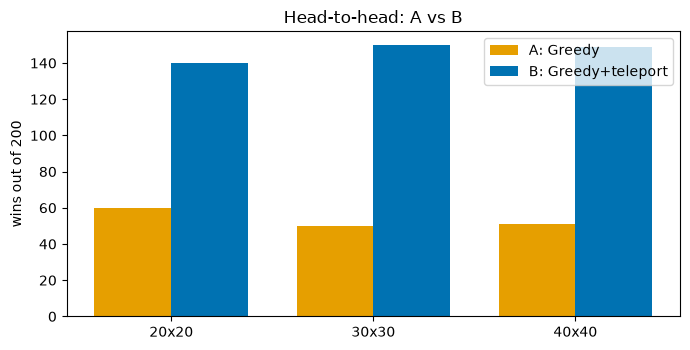

In [12]:
np.random.seed(43)
rows = []
for n in (20, 30, 40):
    a, b, m, s = match(strategies["A: Greedy"], strategies["B: Greedy+teleport"], n, runs=200)
    rows.append({"arena": f"{n}x{n}", "A: Greedy wins": a, "B: Greedy+teleport wins": b, "monster wins": m,
                 "B win rate": f"{100 * b / 200:.0f}%"})
head_to_head = pd.DataFrame(rows)
display(head_to_head)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(head_to_head)); w = 0.38
ax.bar(x - w / 2, head_to_head["A: Greedy wins"], w, label="A: Greedy", color="#e69f00")
ax.bar(x + w / 2, head_to_head["B: Greedy+teleport wins"], w, label="B: Greedy+teleport", color="#0072b2")
ax.set_xticks(x, head_to_head["arena"]); ax.set_ylabel("wins out of 200"); ax.set_title("Head-to-head: A vs B")
ax.legend(); plt.tight_layout(); plt.show()

**Thí nghiệm 3 – Hợp tác.** Trong môi trường cạnh tranh, mỗi hunter chỉ thắng khi *chính nó* bắt được quái vật. Ta chuyển sang **hợp tác**: hai hunter thuộc cùng một đội, đội thắng khi *một trong hai* bắt được quái vật, và chúng chia sẻ thông tin qua một đối tượng dùng chung (`shared`). Vì vị trí quái vật đã là công khai nên thông tin cần chia sẻ là **vị trí của mỗi thợ săn**. Chúng ta dùng nó để phân vai:

* hunter *gần* quái vật hơn là **chaser**: luôn đuổi theo (không teleport, vì sẽ mất lợi thế);
* hunter *xa* hơn là **scout**: teleport nếu khoảng cách $> n/2$ (để phủ vị trí khác), ngược lại cũng đuổi theo.

Giả thuyết: phân vai giúp hai hunter không bỏ lỡ lợi thế đang có (chaser giữ vị trí đang gần) và vẫn tận dụng được các lần "đánh cược" bằng teleport (scout). Ta đo số bước để đội bắt được quái vật, so với hai hunter độc lập cùng dùng Strategy A (Greedy) hoặc cùng dùng Strategy B (Greedy+teleport).

pair,Independent A + A,Independent B + B,Cooperating team (roles)
arena,,,
20x20,9.6,7.0,7.4
30x30,14.4,9.4,10.8
40x40,20.2,12.3,14.2


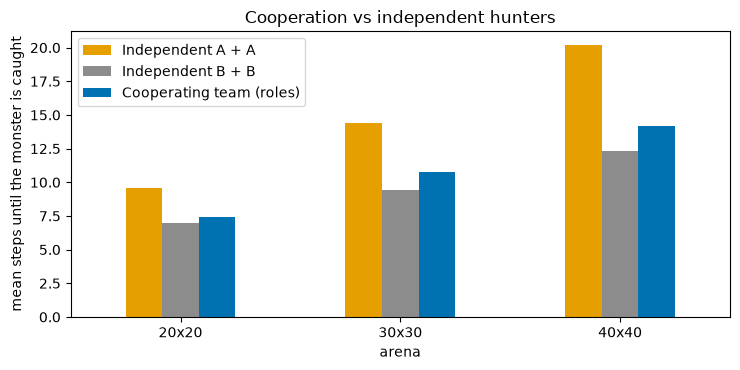

In [13]:
def make_team(n):
    """Two cooperating hunters that share their positions through `shared`."""
    shared = {}

    def make_member(seat):
        other = 2 if seat == 1 else 1
        def member(hunter_location, monster_location):
            me, m = np.asarray(hunter_location), np.asarray(monster_location)
            shared[seat] = me.copy()                                   # publish my position
            d_me = np.abs(m - me).sum()
            d_other = np.abs(m - shared[other]).sum() if other in shared else np.inf
            farther = d_me > d_other or (d_me == d_other and seat == 2)   # role: scout vs chaser
            if farther and d_me > n / 2:
                return "teleport"
            return step_toward(me, m)
        return member
    return make_member(1), make_member(2)

def team_time(make_pair, n, runs=300, max_steps=200):
    steps = []
    for _ in range(runs):
        h1, h2 = make_pair(n)
        winner, s = arena_environment(h1, h2, monster_agent_function_simple, n=n, max_steps=max_steps)
        steps.append(s)                                                # steps until *either* hunter caught it
    steps = np.array(steps, dtype=float)
    return np.nanmean(steps), np.mean(np.isnan(steps))

pairs = {
    "Independent A + A": lambda n: (greedy_hunter, greedy_hunter),
    "Independent B + B": lambda n: (make_teleport_hunter(n), make_teleport_hunter(n)),
    "Cooperating team (roles)": make_team,
}
np.random.seed(44)
rows = []
for n in (20, 30, 40):
    for name, mk in pairs.items():
        mean_steps, fail = team_time(mk, n)
        rows.append({"arena": f"{n}x{n}", "pair": name, "mean steps to catch": round(mean_steps, 1)})
coop = pd.DataFrame(rows).pivot(index="arena", columns="pair", values="mean steps to catch")[list(pairs)]
display(coop)

ax = coop.plot.bar(rot=0, figsize=(7.5, 3.8), color=["#e69f00", "#8c8c8c", "#0072b2"])
ax.set_ylabel("mean steps until the monster is caught"); ax.set_title("Cooperation vs independent hunters")
ax.legend(title=None); plt.tight_layout(); plt.show()

## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

* **Chiến lược cuối cùng:** Strategy B — *greedy chase + teleport khi ở xa*. Mỗi bước hunter đi một ô theo trục có chênh lệch lớn hơn tới quái vật (giảm khoảng cách Manhattan đúng 1 đơn vị mỗi bước), và nếu khoảng cách $> n/2$ thì `teleport`. Vì hunter luôn thấy vị trí quái vật và quái vật di chuyển chậm (đứng yên 50% thời gian), mỗi bước đi đều đưa hunter tới gần đích hơn nên số bước xấp xỉ khoảng cách ban đầu. Trong 100 trận đấu với hunter ngẫu nhiên, mỗi chiến lược thắng 97–100 trận, hunter ngẫu nhiên chỉ thắng 0–3 trận và quái vật không thắng trận nào.
* **So sánh trực tiếp:** ở 20×20, 30×30 và 40×40 Strategy B thắng Strategy A lần lượt 70%, 75% và 74,5% số trận (đã đổi ghế để loại bỏ lợi thế của hunter 1). Số bước trung bình của người thắng cũng thấp hơn nhiều so với A (khi đấu với hunter ngẫu nhiên: 9,0 so với 12,9 bước ở 20×20; 11,4 so với 20,6 ở 30×30; 15,6 so với 26,8 ở 40×40).
* **Teleport:** dùng, nhưng chỉ khi khoảng cách $> n/2$. Một điểm rơi ngẫu nhiên có khoảng cách kỳ vọng tới quái vật xấp xỉ $2n/3$, nên nếu hunter đang xa hơn mức đó thì việc nhảy (tốn 1 bước) có kỳ vọng tốt hơn nhiều so với đi bộ. Trong môi trường cạnh tranh, cuộc đua quyết định bởi người *đến trước*, và teleport tạo ra cơ hội đánh cược mà hunter đi bộ không có. Ngược lại, khi hunter đang ở gần quái vật thì teleport sẽ gần như chắc chắn làm mất lợi thế, nên không dùng.
* **Ảnh hưởng của kích thước:** arena lớn hơn thì khoảng cách trung bình ban đầu lớn hơn ($\approx 2n/3$), số bước tăng gần tuyến tính: Strategy A tăng từ 12,9 (20×20) lên 26,8 (40×40) bước, nhưng Strategy B tăng chậm hơn (9,0 → 15,6) vì arena lớn có nhiều tình huống xuất phát ở xa, chính là lúc teleport hữu ích nhất. Hunter ngẫu nhiên hầu như không thay đổi thứ hạng (đều thua) nhưng cơ hội may mắn của nó giảm khi arena lớn. Trong trận A-B, tỉ lệ thắng của B ổn định ở khoảng 70–75%.

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

> Agent quái vật nhận `monster_pos` và vị trí của cả hai hunter nên có thể:
>
> * **Chạy khỏi hunter gần nhất:** khi có hunter trong bán kính nhỏ, chọn hướng làm *tăng* khoảng cách Manhattan tới hunter gần nhất (hoặc tối đa hoá khoảng cách tối thiểu tới cả hai hunter); nếu hunter ở xa thì đứng yên để không tốn nước đi.
> * **Tránh góc và tường:** ưu tiên ô có nhiều ô lân cận hợp lệ để không tự dồn mình vào chỗ chết.
> * **Chống teleport:** teleport có thể rơi ngay cạnh quái vật nên quái vật cần luôn tránh xa cả hai hunter thay vì chỉ hunter gần nhất.
> * **Khó đoán:** thêm nhiễu ngẫu nhiên vào nước đi để hunter không thể dự đoán.
>
> Lưu ý quái vật không nên quá nhanh (ví dụ luôn di chuyển 1 ô/bước khi bị đuổi) vì khi đó hunter đi bộ sẽ không bao giờ đến gần và chỉ còn teleport ngẫu nhiên là cách bắt.

# More Work (optional)

* Improve the monster agent so it tries to run away from the hunters. Don;t make the monster too fast or the hunters will never be able to catch it.
* How could the two hunter agents work together? You need to think about information sharing. This can be implemented by the two agent functions sharing a single Python class or the environment could be expanded by an action "shout" that lets the other agent perceive a message.

## Đề xuất: từ môi trường cạnh tranh sang hợp tác

Để biến môi trường thành hợp tác ta thay đổi **performance measure** thành *đội thắng khi một trong hai hunter bắt được quái vật* (số bước của đội = số bước tới lần bắt đầu tiên), và cho phép hunter **chia sẻ thông tin**. Hai cách thực hiện:

1. **Đối tượng dùng chung** (đã cài trong `make_team`): hai hàm agent cùng ghi/đọc một `dict` chứa vị trí của từng hunter.
2. **Hành động `shout`** thêm vào môi trường: hunter gửi một tin nhắn (vị trí của nó, vị trí quái vật nghe được, mục tiêu đang đuổi theo) mà hunter kia nhận ở bước sau.

Thông tin nên chia sẻ và cách dùng:

* **Vị trí quái vật:** ở phiên bản này đã công khai nên không cần chia sẻ. Trong phiên bản đơn tác tử (chỉ biết vị trí sau khi `listen`) thì chia sẻ kết quả `listen` rất có giá trị: một hunter nghe, cả hai cùng biết, giảm một nửa chi phí nghe.
* **Vị trí và ý định của hunter:** cho phép *phân vai* (chaser/scout, như `make_team`) hoặc **bao vây (pincer)**: hai hunter tiến về hai phía đối diện của quái vật để nó không thể chạy thoát khi quái vật có tính chạy trốn.
* **Chống trùng lặp:** không để cả hai đi theo cùng một đường; ví dụ hunter 1 giảm chênh lệch theo hàng trước, hunter 2 theo cột trước.

**Kết quả thực nghiệm (Thí nghiệm 3):** với quái vật hiện tại (thụ động, chỉ đi ngẫu nhiên) việc phân vai chaser/scout *không* thắng được hai hunter độc lập cùng dùng Strategy B (ví dụ 7,4 so với 7,0 bước ở 20×20). Đội hợp tác chỉ tốt hơn hai hunter độc lập cùng dùng Strategy A. Lý do: hai lần teleport độc lập đã là "hai lần đánh cược" và cách tốt nhất khi quái vật đứng yên là teleport độc lập nhiều lần; nếu phân vai cho một hunter giữ vị trí thì đội mất một lần đánh cược. Lợi ích của hợp tác sẽ lớn hơn khi (a) quái vật chạy trốn, nên cần bao vây, hoặc (b) thông tin về quái vật không đầy đủ (như `listen`), khi việc chia sẻ thông tin thực sự tăng lượng thông tin của đội.